[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/santialferez/FDLE/blob/main/S2_CNN/S2_CNN_STUDENT.ipynb)

# CNN II: architectures, what CNNs see and transfer learning

**Foundations of Deep Learning for Engineering · Convolutional networks, Session 2 of 2 (week 10)** · EEBE, UPC

In Session 1 you built a small CNN. Today you look inside famous CNNs and reuse one:

1. **Architectures**: where VGG-16 keeps its 138 million parameters, and why ResNet adds its input back (y = x + F(x)),
2. **What a CNN looks at**: first-layer filters and feature maps; as ★ optional extras, Grad-CAM heat maps and an image that fools the network,
3. **Transfer learning**: a ResNet18 trained on ImageNet learns CIFAR-10 from only 5,000 images,
4. **Segmentation**: a class for every pixel.

Work **in pairs** in Google Colab. *Runtime → Change runtime type → T4 GPU*.

**Start now:** run `S2·0` (Part 0, about 20 s), then do the warm-up W1 to W4 on your own. Each lab of the session is a short block of cells; every lab works after `S2·0` alone, so if you are stuck in one lab you can still do the next one.

### How to use this notebook

| Icon | Meaning |
|:-:|:-|
| ▶ | run the cell as it is |
| ✏️ **TODO** | complete the code: replace every `___` with the right expression |
| ❓ | closed question: choose an option or give a number |
| 💬 | open question: discuss with your partner and write two or three sentences |
| 🔬 | experiment: change a setting and watch what happens |
| ✅ | self-check: prints ✅ when your code is right |
| ★ | optional extra for fast pairs: skip it if you are short of time |
| **REPORT** | the last line of each lab: the numbers you write down and share in class, exactly as printed |

Nothing in this notebook is graded. Change things, break things, and compare.

**You do not need to understand every line.** The long helper cells (`S2·0`, `L3·2`) are tools: run them. What matters are the ✏️ lines you complete and the numbers you report.

**Code companion.** Every cell is explained step by step, with diagrams, in the code companion: https://santialferez.github.io/FDLE/S2_CNN/S2_CNN_code_companion.html

**About LLMs.** You may use an LLM (ChatGPT, Claude, Gemini, ...) to understand an error message or a concept. Do not use it to fill the blanks: the blanks are exactly the lines you should be able to write yourself.

## Outline

Run **Part 0** first. The warm-up is for the first 25 minutes, on your own. Each lab is a short block of cells done in pairs at the time in the table; it ends with a **REPORT** line. Every lab works after Part 0 alone.

| Part | Clock | Steps | You report | Slides |
|:-|:-:|:-|:-|:-:|
| Part 0 · Setup | 12:00, first thing | ▶ S2·0 |  |  |
| Warm-up · Finish Session 1 | 12:00 to 12:25 | ✏️ W1 · ✏️ W2 · ✏️ W3 · ▶ W4 · ❓ | CIFAR-10 accuracy (%) of the MLP and of your CNN | 2 |
| Lab 1 · Look inside VGG-16 and ResNet18 | 12:52 to 13:08 | ▶ L1·1 · ✏️ TODO 1 · ✏️ TODO 2 · ✏️ TODO 3 · ▶ L1·3 · ★ optional · 💬 ❓ | % of the parameters in the FC layers (VGG-16, ResNet18) and the gradient ratio skip/plain | 9, 10, 11 |
| Lab 2 · What the first and the last layers see | 13:26 to 13:43 | ▶ L2·1 · ✏️ TODO 1 · ★ optional · ✏️ ★ Optional A · ✏️ ★ Optional B · ★ 💬 ★ ❓ | layer4: number of maps × size · pixels per cell | 15, 16, 17 |
| Lab 3 · Transfer learning: reuse 11 million weights | 14:33 to 15:03 (3a until 14:46) | ▶ L3·1 · ▶ L3·2 · ✏️ TODO 1 · ✏️ TODO 2 · 🔬 TODO 3 · ★ optional · ❓ ❓ 💬 | accuracy (%) after feature extraction (3a); after fine-tuning (3b); with a learning rate 100 times too large (🔬) | 21, 22, 23 |
| Lab 4 · Upsample, then segment the cat | 15:27 to 15:36 | ✏️ TODO 1 · ▶ L4·2 · ★ optional · ❓ | the % of the pixels of the cat photo labelled "cat" | 28, 30 |
| Summary | 15:42 |  |  |  |

Slide numbers are those of the lecture deck (title slide = 1).

## Part 0 · Setup ▶

Run this cell first (about 20 s on a T4). It:

- imports the libraries and finds the GPU,
- defines the helpers of Session 1: `check`, `set_seed`, `count_params`, `evaluate`, `fit`, `show_results`, `show_grid`, and `report_line`, which prints the **REPORT** line of each lab,
- loads CIFAR-10 (50,000 training and 10,000 test photos, 3 × 32 × 32),
- loads **ResNet18 pretrained on ImageNet** (11.7 million parameters, 1,000 classes) and the names of its classes,
- loads four test photos: a cat, an astronaut, a coffee cup and a rocket.

What comes out (you will use these names later):

- `CIFAR_X_TRAIN` (50000, 3, 32, 32) and `CIFAR_X_TEST` (10000, 3, 32, 32): photos as integers 0 to 255; `CIFAR_Y_TRAIN`, `CIFAR_Y_TEST`: labels 0 to 9,
- `resnet`: the pretrained network; `categories`: its 1,000 class names,
- `PHOTOS_224["cat"]` (and `"astronaut"`, `"coffee"`, `"rocket"`): one photo as a tensor (1, 3, 224, 224) with pixels in [0, 1].

You do not need to read this cell: it is a toolbox.

In [ ]:
# ▶ S2·0
# You do not need to read this cell: it is a toolbox. Run it once, at the start.
import os, io, time, json, copy, random, contextlib, warnings, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torchvision
from torchvision.models import ResNet18_Weights

T0_SETUP = time.time()
# FAST=1: tiny subsets and 1 epoch (only to test the notebook on a CPU)
FAST = os.environ.get("FAST") == "1"
device = "cuda" if torch.cuda.is_available() else "cpu"     # "cuda" = the GPU
print("PyTorch", torch.__version__, "· torchvision", torchvision.__version__, "· device:", device,
      "· FAST mode" if FAST else "")
if device == "cpu":
    print("No GPU: Runtime → Change runtime type → T4 GPU "
          "(the notebook also runs on a CPU, only much slower).")
with warnings.catch_warnings():            # same arithmetic on every GPU: no TF32 (a T4 has none anyway)
    warnings.simplefilter("ignore")
    try:
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False
    except Exception:
        pass

MLP_COLOR, CNN_COLOR = "#C9423A", "#1F8A8A"     # red = MLP, teal = CNN in every chart
RESULTS = []                                     # one row per trained model (filled by fit and train_tl)
REPORTS = {}                                     # the REPORT line of each lab


# ======== small helpers (the same as in Session 1)
def set_seed(s=0):
    """Same seed -> same random numbers -> same results (reproducibility)."""
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


def check(cond, ok_msg, hint):
    """Self-check: prints ✅ when the condition holds, otherwise ❌ with a hint. Nothing is graded."""
    if cond:
        print("✅ " + ok_msg)
    else:
        print("❌ Not yet. Hint: " + hint)


def count_params(model):
    """Number of trainable parameters (weights and biases with requires_grad=True)."""
    total = 0
    for p in model.parameters():
        if p.requires_grad:              # frozen parameters (requires_grad=False) are not counted
            total += p.numel()           # numel = number of elements of the tensor
    return total


@torch.no_grad()                         # no gradients needed to predict: faster, less memory
def predict(model, X, batch_size=1000):
    """Predicted class of every image in X, computed in batches of 1,000 so the GPU memory is enough."""
    model.eval()
    preds = []
    for i in range(0, len(X), batch_size):
        logits = model(X[i:i + batch_size])          # (batch, 10): one score per class
        preds.append(logits.argmax(dim=1))          # (batch,): the class with the largest score
    return torch.cat(preds)


def evaluate(model, X, y):
    """Accuracy of the model on images X with labels y: a number between 0 and 1."""
    correct = (predict(model, X) == y).float()      # 1.0 where the prediction is right, else 0.0
    return correct.mean().item()


def fit(model, X_train, y_train, X_val, y_val, epochs=2, lr=1e-3, batch_size=128, name=None):
    """Mini-batch training with Adam and cross-entropy (Session 1); the data stay on `device`.
    Prints one line per epoch, returns dict(train_loss, val_acc) and adds a row to RESULTS."""
    name = name or model.__class__.__name__
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()              # takes logits: no softmax in forward
    hist = dict(train_loss=[], val_acc=[])
    n, t0 = len(X_train), time.time()
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n, device=X_train.device)          # a new random order every epoch
        total = torch.zeros((), device=X_train.device)          # sum of the losses of this epoch
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]                          # the indices of one mini-batch
            xb, yb = X_train[idx], y_train[idx]
            loss = loss_fn(model(xb), yb)        # 1. forward, 2. loss
            optimizer.zero_grad()
            loss.backward()                      # 3. backward (gradients)
            optimizer.step()                     # 4. update the parameters
            total += loss.detach() * len(idx)
        hist["train_loss"].append(total.item() / n)
        hist["val_acc"].append(evaluate(model, X_val, y_val))
        print(f"{name} · epoch {epoch + 1}/{epochs} · train loss {hist['train_loss'][-1]:.4f} · "
              f"val acc {100 * hist['val_acc'][-1]:.1f}% · {time.time() - t0:.0f} s")
    acc = hist["val_acc"][-1]
    RESULTS.append(dict(name=name, params=count_params(model), val_acc=acc,
                        errors=int(round((1 - acc) * len(y_val))), n_val=len(y_val),
                        epochs=epochs, time_s=round(time.time() - t0, 1)))
    return hist


def result(name):
    """The last row of RESULTS with this name."""
    rows = [r for r in RESULTS if r["name"] == name]
    return rows[-1]


def show_results():
    """Print the table of every model trained so far."""
    print(f"{'model':42s} {'params':>11s} {'val acc':>8s}   {'time':>6s}")
    for r in RESULTS:
        print(f"{r['name']:42s} {r['params']:>11,} {100 * r['val_acc']:7.1f}%   {r['time_s']:5.1f} s")


def show_grid(images, titles=None, ncols=8, size=1.4, cmap="gray"):
    """Show a few images (N, C, H, W) or (N, H, W) in a grid; each image is scaled to [0, 1]."""
    # plotting only: you can skip this
    images = images.detach().float().cpu()
    if images.ndim == 3:
        images = images.unsqueeze(1)
    n = len(images)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * 1.15), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i >= n:
            continue
        im = images[i]
        im = (im - im.min()) / (im.max() - im.min() + 1e-8)
        if im.shape[0] == 1:
            ax.imshow(im[0], cmap=cmap)
        else:
            ax.imshow(im.permute(1, 2, 0))
        if titles is not None and i < len(titles) and titles[i]:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout(); plt.show()


def report_line(lab, text):
    """Print the REPORT line of a lab (say it aloud in class); keep it for the summary."""
    REPORTS[lab] = text
    print(f"REPORT: {text}")


def report():
    """Every REPORT line of the session, in one table, then the ★ optional results of Lab 2."""
    if not REPORTS:
        print("No REPORT line yet: run the labs first.")
    for lab, text in REPORTS.items():
        print(f"{lab:10s} REPORT: {text}")
    lab2 = REF.get("lab2", {})                   # the ★ cells of Lab 2 fill these values (None = skipped)
    if lab2.get("cam_cell"):
        cam_txt = f"hottest cell {tuple(lab2['cam_cell'])} for '{lab2.get('cam_class')}'"
    else:
        cam_txt = "★ not done"
    if lab2.get("fgsm_eps") is not None:
        fgsm_txt = f"smallest ε {lab2['fgsm_eps']} · new class {lab2.get('fgsm_class')}"
    else:
        fgsm_txt = "★ not done"
    print(f"{'Lab 2 ★ A':10s} Grad-CAM: {cam_txt}")
    print(f"{'Lab 2 ★ B':10s} FGSM: {fgsm_txt}")


# ======== reference numbers for the lecturer's slides and quizzes: you can skip this
REF = {"warmup": {"mlp": {"params": None, "val_acc": None, "time_s": None},
                  "cnn": {"params": None, "val_acc": None, "time_s": None}},
       "lab1": {"vgg_total": None, "vgg_fc1": None, "vgg_fc_share": None, "resnet_total": None,
                "resnet_fc_share": None, "grad_plain": None, "grad_skip": None, "grad_ratio": None,
                "top1": {"cat": None, "astronaut": None, "coffee": None, "rocket": None}},
       "lab2": {"cell_px": None, "layer4_shape": None,
                "cam_class": None, "cam_cell": None, "fgsm_eps": None, "fgsm_class": None},
       "lab3": {"n_train": None, "n_val": None, "img_size": None,
                "scratch5k": {"val_acc": None, "time_s": None},
                "fe": {"val_acc": None, "time_s": None, "trainable": None},
                "ft": {"val_acc": None, "time_s": None, "trainable": None},
                "bad_lr": {"val_acc": None, "time_s": None}},
       "lab4": {"up_shape": None, "cat_pct": None},
       "device": device, "gpu": torch.cuda.get_device_name(0) if device == "cuda" else "cpu",
       "torch": torch.__version__, "fast": FAST}


def save_reference(path=None, quiet=False):
    """Write REF to s2_reference.json (s2_reference_fast.json under FAST). Never raises."""
    try:
        path = path or ("s2_reference_fast.json" if FAST else "s2_reference.json")
        with open(path, "w") as f:
            json.dump(REF, f, indent=1, ensure_ascii=False)
        if not quiet:
            print("reference numbers written to", os.path.abspath(path))
    except Exception as e:                                # never break the notebook
        print("(could not write the reference file:", repr(e)[:100], ")")


# ======== CIFAR-10: photos as integers 0 to 255 (uint8), shape (N, 3, 32, 32), kept on the CPU
DATA = "./data"
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
HF_CIFAR = "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/"


def cifar10_local(split):
    """A copy already on disk (torchvision format), no download."""
    ds = torchvision.datasets.CIFAR10(DATA, train=(split == "train"), download=False)
    return ds.data, torch.tensor(ds.targets)


def cifar10_from_huggingface(split):
    """The official CIFAR-10 mirrored on Hugging Face (one parquet file, each photo stored as PNG bytes)."""
    import pandas as pd
    from PIL import Image
    df = pd.read_parquet(HF_CIFAR + f"{split}-00000-of-00001.parquet")
    imgs = []
    for d in df["img"]:
        png = Image.open(io.BytesIO(d["bytes"]))      # decode one PNG photo
        imgs.append(np.array(png))                    # (32, 32, 3) integers 0 to 255
    return np.stack(imgs), torch.tensor(df["label"].to_numpy())   # (N, 32, 32, 3), labels (N,)


def cifar10_from_torchvision(split):
    """The original site (www.cs.toronto.edu), sometimes very slow."""
    ds = torchvision.datasets.CIFAR10(DATA, train=(split == "train"), download=True)
    return ds.data, torch.tensor(ds.targets)


# try the sources in order: a local copy, Hugging Face (fast on Colab), the original site
loaders = [("Hugging Face mirror", cifar10_from_huggingface),
           ("original site (slow)", cifar10_from_torchvision)]
if os.path.isdir(os.path.join(DATA, "cifar-10-batches-py")):
    loaders.insert(0, ("copy in ./data", cifar10_local))
CIFAR_OK = False
for where, load in loaders:
    try:
        tr_np, CIFAR_Y_TRAIN = load("train")
        te_np, CIFAR_Y_TEST = load("test")
        # (N, 32, 32, 3) -> (N, 3, 32, 32): PyTorch wants the channels first
        CIFAR_X_TRAIN = torch.as_tensor(np.asarray(tr_np)).permute(0, 3, 1, 2).contiguous()
        CIFAR_X_TEST = torch.as_tensor(np.asarray(te_np)).permute(0, 3, 1, 2).contiguous()
        CIFAR_OK = True
        print(f"CIFAR-10 from the {where}")
        break
    except Exception as e:
        print(f"CIFAR-10 from the {where} failed:", repr(e)[:100])
if not CIFAR_OK:                                  # last resort: Fashion-MNIST made to look like CIFAR-10
    print("-> using Fashion-MNIST instead (resized to 3 × 32 × 32)")
    f_tr = torchvision.datasets.FashionMNIST(DATA, train=True, download=True)
    f_te = torchvision.datasets.FashionMNIST(DATA, train=False, download=True)

    def to_3x32(x):
        x = F.interpolate(x.unsqueeze(1).float(), size=32, mode="bilinear", align_corners=False)
        return x.round().clamp(0, 255).to(torch.uint8).repeat(1, 3, 1, 1)

    CIFAR_X_TRAIN, CIFAR_Y_TRAIN = to_3x32(f_tr.data), f_tr.targets.clone()
    CIFAR_X_TEST, CIFAR_Y_TEST = to_3x32(f_te.data), f_te.targets.clone()
    CIFAR_CLASSES = f_tr.classes
print(f"train {tuple(CIFAR_X_TRAIN.shape)} · test {tuple(CIFAR_X_TEST.shape)} · uint8 · "
      f"CIFAR_OK = {CIFAR_OK}")

# ======== ResNet18 pretrained on ImageNet (45 MB, downloaded once) and its 1,000 class names
weights = ResNet18_Weights.DEFAULT
categories = weights.meta["categories"]                  # a list of 1,000 names, e.g. categories[0] = "tench"
resnet = torchvision.models.resnet18(weights=weights).eval().to(device)
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)     # one mean per colour channel
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)      # one std per colour channel


def imagenet_norm(x):
    """Pixels in [0, 1] -> the normalization ResNet18 was trained with (ImageNet mean and std per channel)."""
    return (x - IMAGENET_MEAN.to(x.device)) / IMAGENET_STD.to(x.device)


# ======== four photos from scikit-image (no download; GitHub as a fallback)
PHOTO_FILES = {"cat": ("chelsea", "png"), "astronaut": ("astronaut", "png"),
               "coffee": ("coffee", "png"), "rocket": ("rocket", "jpg")}


def get_photo(key):
    """RGB uint8 array (H, W, 3) of one test photo."""
    name, ext = PHOTO_FILES[key]
    try:
        import skimage.data
        return getattr(skimage.data, name)()
    except Exception:
        pass
    try:
        from PIL import Image
        url = f"https://raw.githubusercontent.com/scikit-image/scikit-image/main/skimage/data/{name}.{ext}"
        with urllib.request.urlopen(url, timeout=20) as r:
            return np.array(Image.open(io.BytesIO(r.read())).convert("RGB"))
    except Exception:
        print(f"(photo '{key}' not found: using a CIFAR-10 test image instead)")
        index = {"cat": 0, "astronaut": 1, "coffee": 2, "rocket": 3}[key]
        return CIFAR_X_TEST[index].permute(1, 2, 0).numpy()


def to_tensor(arr):
    """uint8 (H, W, 3) -> float (1, 3, H, W) with values in [0, 1]."""
    x = torch.as_tensor(np.ascontiguousarray(arr))      # (H, W, 3)
    x = x.permute(2, 0, 1).float() / 255                  # (3, H, W), values in [0, 1]
    return x.unsqueeze(0)                                 # (1, 3, H, W): a batch of one photo


def center_224(x, size=224):
    """Resize the short side to 224 and cut the central 224 × 224 square (what ResNet18 expects)."""
    h, w = x.shape[-2:]
    s = size / min(h, w)                                  # scale factor for the short side
    new_h, new_w = max(size, round(h * s)), max(size, round(w * s))
    x = F.interpolate(x, size=(new_h, new_w), mode="bilinear", antialias=True, align_corners=False)
    top, left = (new_h - size) // 2, (new_w - size) // 2  # where the central square starts
    return x[..., top:top + size, left:left + size].clamp(0, 1)


PHOTOS_FULL = {}                                          # native size, used in Lab 4
PHOTOS_224 = {}                                           # (1, 3, 224, 224), used in Labs 1 and 2
for key in PHOTO_FILES:
    PHOTOS_FULL[key] = to_tensor(get_photo(key)).to(device)
    PHOTOS_224[key] = center_224(PHOTOS_FULL[key].cpu()).to(device)
    print(f"photo {key:10s} {tuple(PHOTOS_FULL[key].shape[-2:])} -> {tuple(PHOTOS_224[key].shape)}")
n_resnet = sum(p.numel() for p in resnet.parameters())
print(f"ResNet18: {n_resnet:,} parameters, {len(categories)} classes")
print(f"setup ready in {time.time() - T0_SETUP:.0f} s")

## Warm-up · Finish Session 1 (on your own, 12:00 to 12:25)

*Slide: "Start now, in pairs" (slide 2).*

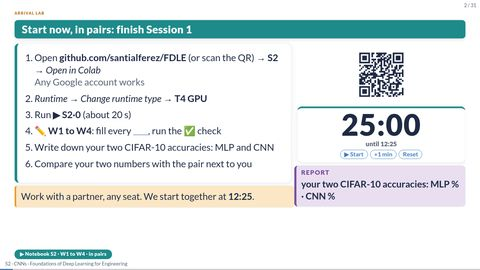

<sub>Slide 2 · Start now</sub>

In Session 1 we ran out of time before the CIFAR-10 result. Finish it now, in pairs, without the lecturer:

1. **W1** and **W2**: the two formulas of Session 1 as Python functions.
2. **W3**: write the CIFAR-10 `ConvNet` yourself.
3. **W4**: train the MLP and your ConvNet on CIFAR-10 and write down the two accuracies.

Each ✏️ cell has blanks `___`. Replace them, run the cell, then run the ✅ cell below it. Stuck? Read the hint, ask the pair next to you. When you finish W4, compare your two CIFAR-10 accuracies with the pair next to you.

**You report:** CIFAR-10 accuracy (%) of the MLP and of your CNN

### ✏️ W1 · The output-size formula

For an input of size J, a kernel M, padding P and stride S, the output size is

$$\frac{J + 2P - M}{S} + 1 \quad\text{(rounded down)}$$

Write it with `//` (integer division).

In [ ]:
# ✏️ S2·W1
def out_size(J, M, P=0, S=1):
    """Output size of a convolution or pooling: input J, kernel M, padding P, stride S."""
    # TODO: add the padding on both sides, remove the kernel, divide by the stride (integer division)
    return (J + 2 * ___ - ___) // ___ + 1


# four examples: expected 28, 28, 112, 14
print(out_size(28, 3, 1), out_size(32, 5), out_size(224, 7, 3, 2), out_size(28, 2, 0, 2))

In [ ]:
# ▶ S2·W1·check
check(out_size(28, 3, 1) == 28, "(28 + 2 − 3)/1 + 1 = 28: padding 1 keeps the size of a 3 × 3 conv",
      "2 * P, minus M, then // S, plus 1")
check(out_size(32, 5) == 28, "(32 − 5)/1 + 1 = 28 (LeNet's first layer)", "P = 0 and S = 1 by default")
check(out_size(224, 7, 3, 2) == 112, "(224 + 6 − 7)//2 + 1 = 112 (the first layer of ResNet18)",
      "use // for the division by S")
check(out_size(28, 2, 0, 2) == 14, "pooling 2 × 2 with stride 2: 28 → 14",
      "a pooling window is a kernel with M = 2, S = 2")

### ✏️ W2 · Parameters of a convolution

`nn.Conv2d(C_in, C_out, M)` has C_out filters. Each filter sees **all** the input channels, so it has M · M · C_in weights plus 1 bias:

$$(M^2 \cdot C_{in} + 1)\cdot C_{out}$$

In [ ]:
# ✏️ S2·W2
def conv_params(M, C_in, C_out):
    """Weights and biases of nn.Conv2d(C_in, C_out, M)."""
    # TODO: weights of ONE filter (it sees every input channel) plus 1 bias, times the number of filters
    return (M * M * ___ + 1) * ___


# three examples: expected 80, 1168, 224
print(conv_params(3, 1, 8), conv_params(3, 8, 16), conv_params(3, 3, 8))

In [ ]:
# ▶ S2·W2·check
check(conv_params(3, 1, 8) == 80, "conv(1 → 8, 3 × 3): (9·1 + 1)·8 = 80",
      "M * M * C_in weights per filter, plus 1 bias")
check(conv_params(3, 8, 16) == 1168, "conv(8 → 16, 3 × 3): (9·8 + 1)·16 = 1,168",
      "each filter sees all 8 input channels")
check(conv_params(3, 3, 8) == 224 == count_params(nn.Conv2d(3, 8, 3)),
      "conv(3 → 8, 3 × 3) on colour images: (9·3 + 1)·8 = 224, the same as PyTorch",
      "multiply by C_out at the end")

### ✏️ W3 · Write the CIFAR-10 `ConvNet`

The ConvNet of Session 1, now for colour photos of 3 × 32 × 32 pixels:

| layer | output shape | parameters |
|:-|:-|-:|
| input | (N, 3, 32, 32) | |
| conv(3 → 8, 3 × 3, padding 1) + ReLU | (N, 8, 32, 32) | (9 · 3 + 1) · 8 = 224 |
| max-pool 2 | (N, 8, 16, 16) | 0 |
| conv(8 → 16, 3 × 3, padding 1) + ReLU | (N, 16, 16, 16) | (9 · 8 + 1) · 16 = 1,168 |
| max-pool 2 | (N, 16, 8, 8) | 0 |
| flatten | (N, 1,024) | 0 |
| Linear(1,024, 64) + ReLU | (N, 64) | 1,024 · 64 + 64 = 65,600 |
| Linear(64, 10) | (N, 10) | 650 |
| **total** | | **67,642** |

Fill in: the number of input channels, the padding that keeps 32 × 32, and the height × width after two poolings.

- in: a batch of photos (N, 3, 32, 32),
- out: 10 scores per photo (N, 10), one per class (logits, no softmax).

In [ ]:
# ✏️ S2·W3
class ConvNet(nn.Module):
    """conv(3→8) → ReLU → pool → conv(8→16) → ReLU → pool → flatten → Linear(1024, 64) → ReLU → Linear(64, 10)
    (the table above, as PyTorch layers)."""
    def __init__(self):
        super().__init__()
        # TODO: colour photos have how many input channels? Which padding keeps 32 × 32 with a 3 × 3 kernel?
        self.conv1 = nn.Conv2d(___, 8, kernel_size=3, padding=___)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)                        # halves height and width, 0 parameters
        # TODO: 16 channels times (height × width) after two poolings of a 32 × 32 photo
        self.fc1 = nn.Linear(16 * ___, 64)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):                          # x: (N, 3, 32, 32)
        x = F.relu(self.conv1(x))                  # (N, 8, 32, 32)
        x = self.pool(x)                           # (N, 8, 16, 16)
        x = F.relu(self.conv2(x))                  # (N, 16, 16, 16)
        x = self.pool(x)                           # (N, 16, 8, 8)
        x = x.flatten(1)                           # (N, 1024): one long vector per photo
        x = F.relu(self.fc1(x))                    # (N, 64)
        return self.fc2(x)                         # (N, 10) logits, no softmax


set_seed(0)
cnn_w = ConvNet()
out = cnn_w(torch.randn(64, 3, 32, 32))            # a batch of 64 random "photos", only to test the shapes
print("output", tuple(out.shape), "·", f"{count_params(cnn_w):,}", "parameters")

In [ ]:
# ▶ S2·W3·check
check(tuple(out.shape) == (64, 10), "64 photos in, 64 × 10 logits out", "conv1 needs 3 input channels (RGB)")
check(count_params(cnn_w) == 67642, "ConvNet on CIFAR-10 has 67,642 parameters (224 + 1,168 + 65,600 + 650)",
      "padding=1 keeps 32 × 32; two poolings give 32 → 16 → 8, so fc1 sees 16 · 8 · 8 = 1,024 numbers")

### ▶ W4 · CIFAR-10: MLP vs your ConvNet

Both models train 5 epochs on the 50,000 training photos (Adam, learning rate 0.001, batch 128) and are measured on the 10,000 test photos. About 10 s on a T4.

- MLP 3,072 → 64 → 10: 197,322 parameters (it flattens the 3 · 32 · 32 = 3,072 numbers),
- your ConvNet: 67,642 parameters, about one third.

- in: the CIFAR-10 photos as numbers, normalized per colour channel (mean 0, std 1),
- out: one line per epoch for each model, a bar chart, and the REPORT line with the two accuracies.

**Predict first.** Which model will be more accurate? By how many points? Write your guess before you run the cell.

In [ ]:
# ▶ S2·W4
N_W, NV_W, EPOCHS_W = (10_000, 2_000, 1) if FAST else (50_000, 10_000, 5)

# the data: integers 0 to 255 -> floats in [0, 1] -> mean 0 and std 1 per colour channel
xw = CIFAR_X_TRAIN[:N_W].float() / 255                       # (50000, 3, 32, 32)
W_MEAN = xw.mean(dim=(0, 2, 3), keepdim=True)                # (1, 3, 1, 1): one mean per channel
W_STD = xw.std(dim=(0, 2, 3), keepdim=True)                  # (1, 3, 1, 1): one std per channel
Xw_train = ((xw - W_MEAN) / W_STD).to(device)
xw_val = CIFAR_X_TEST[:NV_W].float() / 255                   # (10000, 3, 32, 32)
Xw_val = ((xw_val - W_MEAN) / W_STD).to(device)              # same mean and std as the training photos
yw_train = CIFAR_Y_TRAIN[:N_W].to(device)
yw_val = CIFAR_Y_TEST[:NV_W].to(device)
del xw, xw_val


class MLP(nn.Module):
    """flatten → Linear(3072, 64) → ReLU → Linear(64, 10)."""
    def __init__(self, in_features=3 * 32 * 32, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(),                     # (N, 3, 32, 32) -> (N, 3072)
                                 nn.Linear(in_features, hidden), nn.ReLU(),
                                 nn.Linear(hidden, 10))            # (N, 10) logits

    def forward(self, x):
        return self.net(x)                                # logits, no softmax


# the two models, then 5 epochs of training each
set_seed(0)
mlp_w, cnn_w = MLP(), ConvNet()
check(count_params(mlp_w) == 197322 and count_params(cnn_w) == 67642,
      "MLP 197,322 and ConvNet 67,642 parameters", "finish W3 first: the ConvNet must have 67,642 parameters")
fit(mlp_w, Xw_train, yw_train, Xw_val, yw_val, epochs=EPOCHS_W, name="MLP · CIFAR-10")
fit(cnn_w, Xw_train, yw_train, Xw_val, yw_val, epochs=EPOCHS_W, name="ConvNet · CIFAR-10")
r_mlp, r_cnn = result("MLP · CIFAR-10"), result("ConvNet · CIFAR-10")

# plotting only: you can skip this
plt.figure(figsize=(5.5, 3.4))
for k, (r, col, lab) in enumerate([(r_mlp, MLP_COLOR, "MLP"), (r_cnn, CNN_COLOR, "ConvNet")]):
    plt.bar(k, 100 * r["val_acc"], color=col, width=0.6)
    plt.text(k, 100 * r["val_acc"] + 1.5, f"{100 * r['val_acc']:.1f}%\n{r['params']:,} params",
             ha="center", fontsize=9)
plt.xticks([0, 1], ["MLP", "ConvNet"]); plt.ylim(0, 100); plt.ylabel("validation accuracy (%)")
plt.title("CIFAR-10: a third of the parameters, more accuracy"); plt.tight_layout(); plt.show()

# reference file for the lecturer and the self-checks: you can skip this
for key, r in (("mlp", r_mlp), ("cnn", r_cnn)):
    REF["warmup"][key] = {"params": r["params"], "val_acc": round(r["val_acc"], 4), "time_s": r["time_s"]}
save_reference(quiet=True)
thr_mlp, thr_cnn = (0.30, 0.28) if FAST else (0.45, 0.58)    # reference run (Colab T4): MLP 49.0%, CNN 62.4%
check(r_mlp["val_acc"] > thr_mlp and r_cnn["val_acc"] > thr_cnn,
      f"MLP {100 * r_mlp['val_acc']:.1f}% · ConvNet {100 * r_cnn['val_acc']:.1f}%",
      "rerun W3 and this cell (the models are created again here)")
if not FAST:
    check(r_cnn["val_acc"] > r_mlp["val_acc"], "the ConvNet beats the MLP with one third of the parameters",
          "both models must train for 5 epochs")
acc_mlp, acc_cnn = 100 * r_mlp["val_acc"], 100 * r_cnn["val_acc"]
report_line("Warm-up", f"CIFAR-10 accuracy in % · MLP {acc_mlp:.1f} · CNN {acc_cnn:.1f}")

❓ **W question.** Your guess and your result. Which single layer holds most of the parameters of each model? Why can the ConvNet win with one third of the parameters?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

## Lab 1 · Look inside VGG-16 and ResNet18

*Slide: "Lab 1" (slide 11).*

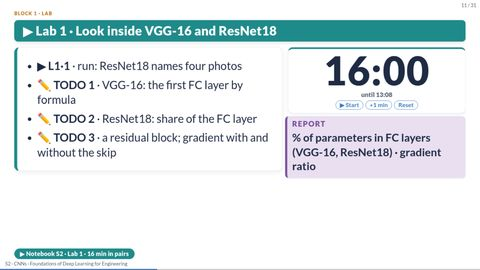

<sub>Slide 11 · Lab 1</sub>

16 minutes, in pairs. Two famous networks:

- **VGG-16** (2014): 13 convolutions, all 3 × 3, then three fully connected (FC) layers. 138 million parameters.
- **ResNet18** (2015): 17 convolutions in **residual blocks** y = x + F(x), then global average pooling and one FC layer. 11.7 million parameters.

Steps: ▶ L1·1 (run), ✏️ TODO 1, TODO 2, TODO 3, then the REPORT line.

**You report:** % of the parameters in the FC layers (VGG-16, ResNet18) and the gradient ratio skip/plain

### ▶ L1·1 · ResNet18 names four photos

ResNet18 was trained on ImageNet: 1.28 million photos of 1,000 classes. We give it our four photos (224 × 224, normalized with the ImageNet mean and standard deviation) and print its top-3 classes with their confidence. The probabilities come from a softmax applied **outside** the model.

- in: one photo (1, 3, 224, 224) with pixels in [0, 1],
- out: 1,000 scores; softmax turns them into probabilities; we print the 3 largest.

**Look at the wrong answers.** "astronaut" and "rocket" are not among the 1,000 ImageNet classes, so the network cannot say them: it must answer with the closest class it knows ("bobsled", "drilling platform"). A classifier always gives an answer; a **low confidence** (here about 9% for the astronaut) is the warning that the answer may be meaningless.

In [ ]:
# ▶ S2·L1·1
@torch.no_grad()                                 # no gradients needed: we only look at the answer
def top_k(x, k=3):
    """The k most likely ImageNet classes of image x (pixels in [0, 1]) as a list of (name, probability)."""
    resnet.eval()
    logits = resnet(imagenet_norm(x))            # (1, 1000): one score per ImageNet class
    probs = F.softmax(logits, dim=1)[0]          # (1000,) probabilities: softmax here, never in the model
    vals, idx = probs.topk(k)                    # the k largest probabilities and their class numbers
    top = []
    for v, i in zip(vals, idx):
        top.append((categories[i], v.item()))
    return top


# plotting only: you can skip the imshow and title lines
fig, ax = plt.subplots(1, 4, figsize=(13, 3.6))
for a, (name, x) in zip(ax, PHOTOS_224.items()):
    top = top_k(x)
    REF["lab1"]["top1"][name] = top[0][0]
    print(f"{name:10s} " + " · ".join(f"{c} {100 * p:.1f}%" for c, p in top))
    a.imshow(x[0].permute(1, 2, 0).cpu()); a.axis("off")
    a.set_title(f"{top[0][0]} ({100 * top[0][1]:.0f}%)", fontsize=10)
plt.tight_layout(); plt.show()

# a low top-1 probability is a warning: maybe the photo shows none of the 1,000 classes
for name, x in PHOTOS_224.items():
    c, p = top_k(x, 1)[0]
    if p < 0.5:
        print(f"warning: '{name}' -> {c} at only {100 * p:.0f}%: the network is not sure "
              f"(is '{name}' one of its classes?)")
check(len(categories) == 1000, "ResNet18 chooses among 1,000 ImageNet classes", "rerun S2·0")

### ✏️ Lab 1 · TODO 1 · VGG-16: where are the 138 million parameters?

*Slide: "VGG-16" (slide 9).*

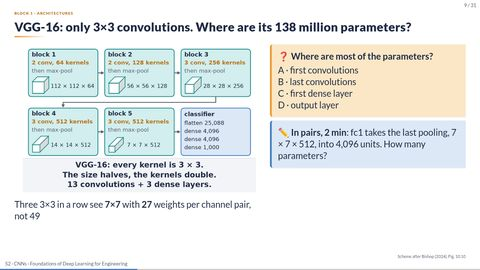

<sub>Slide 9 · VGG-16</sub>

After its last pooling, VGG-16 has 512 feature maps of 7 × 7. They are flattened and go to three FC layers:

- fc1: Linear(7 · 7 · 512 → 4,096), fc2: Linear(4,096 → 4,096), fc3: Linear(4,096 → 1,000).

A Linear layer with n_in inputs and n_out outputs has n_in · n_out weights plus n_out biases. Write fc1 by the formula, then the share of the three FC layers in the whole network. The total comes from `torchvision.models.vgg16(weights=None)`: random weights, nothing is downloaded.

In [ ]:
# ✏️ S2·L1·TODO1
# TODO: fc1 has 7·7·(number of maps) inputs and 4096 outputs; how many biases does it have?
fc1 = 7 * 7 * ___ * 4096 + ___            # weights + biases of Linear(7·7·512 → 4096)
fc2 = 4096 * 4096 + 4096                       # Linear(4096 → 4096)
fc3 = 4096 * 1000 + 1000                       # Linear(4096 → 1000): one output per ImageNet class
fc_total = fc1 + fc2 + fc3

if FAST:                                        # FAST test mode: skip building the 138-million network
    vgg_total = 138_357_544
else:
    vgg = torchvision.models.vgg16(weights=None)     # the real architecture with random weights (no download)
    vgg_total = count_params(vgg)
    print(f"PyTorch: first FC layer of VGG-16 has {count_params(vgg.classifier[0]):,} parameters")
    del vgg                                     # free the memory (138 million numbers)
# TODO: a share is a part divided by the whole
fc_share = fc_total / ___
print(f"fc1 {fc1:,} · three FC layers {fc_total:,} · whole VGG-16 {vgg_total:,}")
print(f"share of the three FC layers: {100 * fc_share:.1f}%   (fc1 alone: {100 * fc1 / vgg_total:.1f}%)")

In [ ]:
# ▶ S2·L1·TODO1·check
check(fc1 == 102_764_544, "fc1 = 7·7·512·4,096 + 4,096 = 102,764,544",
      "25,088 inputs (7 · 7 · 512) times 4,096 outputs, plus 4,096 biases")
check(vgg_total == 138_357_544, "VGG-16 has 138,357,544 parameters", "count_params(vgg16(weights=None))")
check(abs(fc_share - 0.8936) < 0.001, f"the three FC layers hold {100 * fc_share:.1f}% of VGG-16",
      "fc_share = fc_total / vgg_total")
REF["lab1"].update(vgg_total=vgg_total, vgg_fc1=fc1, vgg_fc_share=round(fc_share, 4))

### ✏️ Lab 1 · TODO 2 · ResNet18: how big is its head?

The FC layer of ResNet18 is `resnet.fc`. Count its parameters with `count_params` and divide by the whole network.

- in: the network `resnet` loaded in `S2·0`,
- out: the parameters of its last layer, and their share of the 11.7 million.

In [ ]:
# ✏️ S2·L1·TODO2
print(resnet.avgpool, "->", resnet.fc)          # the last two layers of ResNet18
# TODO: which attribute of resnet is its last (fully connected) layer? It is printed on the line above.
fc_resnet = count_params(resnet.___)
resnet_total = count_params(resnet)
resnet_fc_share = fc_resnet / resnet_total
print(f"ResNet18: fc {fc_resnet:,} of {resnet_total:,} parameters = {100 * resnet_fc_share:.1f}%")

In [ ]:
# ▶ S2·L1·TODO2·check
check(fc_resnet == 513_000, "fc = Linear(512 → 1,000): 512·1,000 + 1,000 = 513,000",
      "count_params(resnet.fc)")
check(resnet_total == 11_689_512 and abs(resnet_fc_share - 0.0439) < 0.0005,
      f"ResNet18 has 11,689,512 parameters; its FC layer only {100 * resnet_fc_share:.1f}%",
      "resnet_fc_share = fc_resnet / resnet_total")
REF["lab1"].update(resnet_total=resnet_total, resnet_fc_share=round(resnet_fc_share, 4))

### ✏️ Lab 1 · TODO 3 · A residual block, and the gradient with and without the skip

*Slide: "ResNet" (slide 10).*

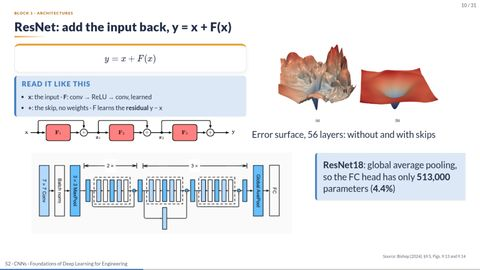

<sub>Slide 10 · ResNet</sub>

A residual block adds its input back: **y = ReLU(x + F(x))**, where F is two layers (here Linear → ReLU → Linear). A plain block computes only y = ReLU(F(x)). Complete the `return` line of the residual block.

In [ ]:
# ✏️ S2·L1·TODO3
class Block(nn.Module):
    """F(x) = Linear → ReLU → Linear. With skip: y = ReLU(x + F(x)). Without: y = ReLU(F(x))."""
    def __init__(self, width, skip=True):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(width, width), nn.ReLU(), nn.Linear(width, width))   # F(x)
        self.skip = skip                         # True: residual block, False: plain block

    def forward(self, x):                        # x: (batch, width); the output has the same shape
        if self.skip:
            # TODO: y = x + F(x): what do we add back to F(x)?
            return F.relu(___ + self.f(x))       # residual block: add the input back
        return F.relu(self.f(x))                 # plain block

In [ ]:
# ▶ S2·L1·TODO3·check
# test: set every weight and bias to 0, so that F(x) = 0, and see what each block returns
blk_skip, blk_plain = Block(4, skip=True), Block(4, skip=False)
for b in (blk_skip, blk_plain):
    for p in b.parameters():
        nn.init.zeros_(p)                        # F(x) = 0: the block has learned "nothing"
x_test = torch.rand(3, 4)                        # positive inputs, as after a ReLU
check(torch.allclose(blk_skip(x_test), x_test),
      "with F = 0 the residual block returns its input: y = x + 0 = x",
      "return F.relu(x + self.f(x)): add the input x to F(x)")
check(torch.all(blk_plain(x_test) == 0), "with F = 0 the plain block returns 0: the signal is lost",
      "do not change the plain branch")

### ▶ L1·3 · The gradient at the first layer, with and without skips

We stack **5 blocks** (10 Linear layers of width 128) plus a Linear(128, 10) output, once with plain blocks and once with residual blocks. Same initialization (PyTorch default), same random batch, at the start of training. We measure the mean size of the gradient that reaches the weights of the **first** layer.

- in: a random batch (64, 128) and random labels; two networks of 5 blocks, plain and residual,
- out: the mean size of the gradient at layer 1 for each network, their ratio, and a plot for 1 to 30 blocks.

This runs on the CPU with a fixed seed, so everybody gets exactly the same numbers.

In [ ]:
# ▶ S2·L1·3
WIDTH, DEPTH = 128, 5                 # 5 blocks = 10 Linear layers


def first_layer_grad(depth, skip, seed=0, width=WIDTH):
    """Mean |gradient| of the weights of the FIRST Linear layer, at initialization, on one random batch."""
    torch.manual_seed(seed)                             # same seed -> same initial weights
    layers = []
    for _ in range(depth):
        layers.append(Block(width, skip))               # depth blocks, all plain or all residual
    layers.append(nn.Linear(width, 10))                 # output layer: 10 class scores
    net = nn.Sequential(*layers)
    g = torch.Generator().manual_seed(1000 + seed)
    x = torch.randn(64, width, generator=g)             # a random batch of 64 inputs: (64, 128)
    y = torch.randint(0, 10, (64,), generator=g)        # random labels: (64,)
    loss = F.cross_entropy(net(x), y)
    loss.backward()                                     # fills .grad of every weight
    first_weights = net[0].f[0].weight                  # the weights of the first Linear of the first block
    return first_weights.grad.abs().mean().item()       # their mean |gradient|


grad_plain = first_layer_grad(DEPTH, skip=False)
grad_skip = first_layer_grad(DEPTH, skip=True)
grad_ratio = grad_skip / grad_plain
print(f"{DEPTH} blocks · gradient at the first layer: plain {grad_plain:.2e} · with skips {grad_skip:.2e}")
print(f"ratio skip / plain: {grad_ratio:,.0f}")
print(f"Meaning: without skips the first layer gets about {grad_ratio:,.0f} times less gradient,")
print(f"so it learns about {grad_ratio:,.0f} times more slowly than with skips.")
print("With y = x + F(x) the gradient has a direct path back through every '+ x',")
print("so even the first layer gets a useful signal.")

# the same measurement for 1 to 30 blocks
depths = list(range(1, 31))
g_plain, g_skip = [], []
for d in depths:
    g_plain.append(first_layer_grad(d, skip=False))
    g_skip.append(first_layer_grad(d, skip=True))

# plotting only: you can skip this
plt.figure(figsize=(7, 3.4))
plt.semilogy(depths, g_plain, "o-", color=MLP_COLOR, ms=3, label="plain blocks")
plt.semilogy(depths, g_skip, "o-", color=CNN_COLOR, ms=3, label="residual blocks (skip)")
plt.axvline(DEPTH, color="grey", ls=":", lw=1)
plt.xlabel("number of blocks (2 Linear layers each)"); plt.ylabel("mean |gradient| at layer 1 (log scale)")
plt.title("The gradient vanishes without skips"); plt.legend(); plt.tight_layout(); plt.show()
print(f"at 30 blocks the ratio is about 10^{np.log10(g_skip[-1] / g_plain[-1]):.0f}")

check(grad_skip > 10 * grad_plain,
      f"the skips keep the gradient {grad_ratio:,.0f} times larger at the first layer",
      "TODO 3: the residual block must return F.relu(x + self.f(x))")
# reference file and REPORT line: you can skip the bookkeeping
REF["lab1"].update(grad_plain=float(f"{grad_plain:.4g}"), grad_skip=float(f"{grad_skip:.4g}"),
                   grad_ratio=round(grad_ratio, 1))
save_reference(quiet=True)
fc_v = 100 * REF["lab1"]["vgg_fc_share"] if REF["lab1"]["vgg_fc_share"] else float("nan")
fc_r = 100 * REF["lab1"]["resnet_fc_share"] if REF["lab1"]["resnet_fc_share"] else float("nan")
report_line("Lab 1", f"% of parameters in FC layers · VGG-16 {fc_v:.1f} · ResNet18 {fc_r:.1f} · "
                     f"gradient ratio skip/plain {grad_ratio:,.0f}")

💬 **Lab 1 · Q1.** VGG-16 keeps 89% of its parameters in its three FC layers; ResNet18 only 4.4% in its one FC layer. What does ResNet18 do just before `fc` that makes its head so small? (Look at the line `AdaptiveAvgPool2d` printed in TODO 2.)

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

❓ **Lab 1 · Q2.** In a residual block y = x + F(x), suppose F learns to output 0. What does the block compute?
(a) zero  (b) the identity, y = x  (c) 2x  (d) random noise

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ★ Optional · Deeper stacks

For fast pairs. How does the ratio grow with the number of blocks? Each plain block shrinks the gradient by about the same factor, so the ratio grows exponentially (a straight line on the log plot above).

In [ ]:
# ▶ S2·L1·STAR
for d in (2, 5, 10, 20, 30):
    ratio = first_layer_grad(d, skip=True) / first_layer_grad(d, skip=False)
    print(f"{d:2d} blocks: ratio skip / plain = {ratio:.3g}")

## Lab 2 · What the first and the last layers see

*Slide: "Lab 2" (slide 16).*

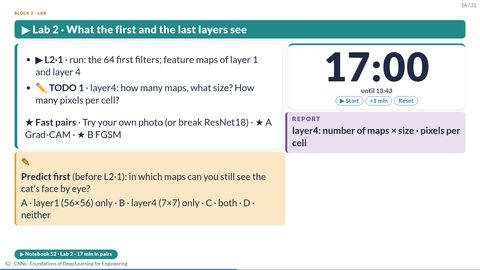

<sub>Slide 16 · Lab 2</sub>

17 minutes, in pairs. **Every pair** does the required part (about 8 minutes): ▶ L2·1 (run), ✏️ TODO 1 (how big is one cell of layer4?), then the REPORT line. Both look at the **cat** photo.

★ **Fast pairs** then have three optional cells (in order of difficulty):

- ★ **Try your own photo (`S2·L2·TRY`)**: no coding needed; test ResNet18 on Hubble galaxies, a microscope slide, a retina scan, or upload a photo from your computer/phone to try to confuse it.
- ★ **Optional A · Grad-CAM**: which region of the coffee photo pushed the score of "espresso"?
- ★ **Optional B · FGSM**: fool the network with a change you cannot see. It does not need Optional A.

If your pair is behind, skip the ★ cells and use the rest of the 17 minutes to finish Lab 1 or the warm-up.

**You report:** layer4: number of maps × size · pixels per cell

### ▶ L2·1 · What the first and the last layers see

- The **64 filters of the first layer** of ResNet18 (`conv1`, each 3 × 7 × 7), shown as small colour images. Look for edges at several angles and colour blobs.
- **Feature maps** of the cat: 8 of the 64 maps after `layer1` (56 × 56, still the shape of the cat) and 8 of the 512 maps after `layer4` (7 × 7, only "where" something important is).

A **forward hook** is a small function that PyTorch calls every time a layer runs; we use it to keep the output of `layer1` and `layer4` without changing the network.

**❓ Predict before you run:** in which maps (`layer1` at 56 × 56, or `layer4` at 7 × 7) will you still recognize the cat's face by eye?

- in: the cat photo (1, 3, 224, 224),
- out: the conv1 weights (64, 3, 7, 7), the maps of layer1 (1, 64, 56, 56) and of layer4 (1, 512, 7, 7), as pictures.

In [ ]:
# ▶ S2·L2·1
w1 = resnet.conv1.weight.detach().cpu()                     # (64, 3, 7, 7): 64 filters, 3 colours, 7 × 7
print("conv1 weights:", tuple(w1.shape))
show_grid(w1, ncols=16, size=0.75)                          # each filter scaled to [0, 1] as an RGB tile

maps = {}                                                   # the hooks put the layer outputs here


def save_output(name):
    """A forward hook: keeps the output of a layer in maps[name]."""
    def hook(module, inp, out):
        maps[name] = out.detach()
    return hook


hook1 = resnet.layer1.register_forward_hook(save_output("layer1"))
hook4 = resnet.layer4.register_forward_hook(save_output("layer4"))
with torch.no_grad():
    resnet(imagenet_norm(PHOTOS_224["cat"]))                # one forward pass: the hooks fill maps
hook1.remove()                                              # always remove hooks you do not need any more
hook4.remove()
print("layer1 output:", tuple(maps["layer1"].shape), "· layer4 output:", tuple(maps["layer4"].shape))
# show 8 maps of each layer (the first image of the batch, channels 0 to 7)
show_grid(maps["layer1"][0, :8], [f"layer1 · map {c}" for c in range(8)], cmap="viridis", size=1.6)
show_grid(maps["layer4"][0, :8], [f"layer4 · map {c}" for c in range(8)], cmap="viridis", size=1.6)
check(tuple(maps["layer4"].shape) == (1, 512, 7, 7), "layer4 gives 512 maps of 7 × 7 for a 224 × 224 photo",
      "rerun S2·0 and this cell")

### ✏️ Lab 2 · TODO 1 · How big is one cell of layer4?

L2·1 kept the output of `layer4` in `maps["layer4"]`. Its shape has four numbers: (photos, maps, height, width). The photo had 224 × 224 pixels; after `layer4` each map has only a few cells per side, so **one cell stands for a square of the photo**. How many pixels is the side of that square?

Fill in two blanks: where the last three numbers of the shape start, and the width of the photo in pixels.

- in: `maps["layer4"]` from L2·1, one photo of 224 × 224 pixels,
- out: `n_maps` (number of maps), `h` and `w` (height and width of one map, in cells), and `cell_px`, the side in pixels of the square that one cell covers.

In [ ]:
# ✏️ S2·L2·TODO1
print("layer4 output:", tuple(maps["layer4"].shape))      # (photos, maps, height, width)
# TODO: skip the first number (1 photo): at which position do the maps, the height and the width start?
n_maps, h, w = maps["layer4"].shape[___:]                 # number of maps, and the size of one map in cells
# TODO: how many pixels wide is the photo? (look at the shape of PHOTOS_224["cat"])
cell_px = ___ // w                                     # pixels of the photo per cell, along one side
print(f"layer4: {n_maps} maps of {h} × {w} cells · one cell = {cell_px} × {cell_px} pixels of the photo")

In [ ]:
# ▶ S2·L2·TODO1·check
check(n_maps == 512, "layer4 has 512 maps", "maps['layer4'].shape is (1, 512, 7, 7): start at position 1")
check((h, w) == (7, 7), "each map has 7 × 7 cells", "n_maps, h, w = maps['layer4'].shape[1:]")
check(cell_px == 32, "one cell covers 32 × 32 pixels: 224 / 7 = 32 (the side was halved five times)",
      "cell_px = 224 // w")
# reference file and REPORT line: you can skip the bookkeeping
REF["lab2"].update(cell_px=int(cell_px), layer4_shape=[int(n_maps), int(h), int(w)])
save_reference(quiet=True)
report_line("Lab 2", f"layer4: {n_maps} maps of {h} × {w} · one cell = {cell_px} × {cell_px} pixels")

### ★ Try your own photo (or break ResNet18)

For fast pairs, right after TODO 1 (no hooks or gradients to write, works after `S2·0` alone). Pick one of the extra built-in photos below (`"hubble"`, `"microscope"`, `"retina"`, or `"cat"`, `"coffee"`, `"astronaut"`, `"rocket"`), **or** set `UPLOAD = True` in Colab to test a photo from your computer or phone.

- What are ResNet18's top-3 guesses? Can you find an image that confuses it?
- Compare `layer1` (56 × 56) and `layer4` (7 × 7) on the new photo.

In [ ]:
# ▶ S2·L2·TRY
PHOTO = "hubble"          # try: "hubble", "microscope", "retina", "cat", "coffee", "astronaut", "rocket"
UPLOAD = False            # set to True in Colab to upload your own photo (jpg/png)

if UPLOAD:
    from google.colab import files
    from PIL import Image
    uploaded = files.upload()
    fname = next(iter(uploaded))
    raw = np.array(Image.open(io.BytesIO(uploaded[fname])).convert("RGB"))
    x_try = center_224(to_tensor(raw)).to(device)
    label_name = fname
elif PHOTO in PHOTOS_224:
    x_try = PHOTOS_224[PHOTO]
    label_name = PHOTO
else:
    import skimage.data
    extra = {"hubble": "hubble_deep_field", "microscope": "immunohistochemistry", "retina": "retina"}
    raw = getattr(skimage.data, extra[PHOTO])()
    x_try = center_224(to_tensor(raw)).to(device)
    label_name = PHOTO

# run ResNet18 once and keep the outputs of layer1 and layer4
try_maps = {}


def keep(name):
    def hook(module, inp, out):
        try_maps[name] = out.detach()
    return hook


h1 = resnet.layer1.register_forward_hook(keep("layer1"))
h4 = resnet.layer4.register_forward_hook(keep("layer4"))
with torch.no_grad():
    resnet.eval()
    probs = F.softmax(resnet(imagenet_norm(x_try)), dim=1)[0]
h1.remove()
h4.remove()

vals, idx = probs.topk(3)
parts = []
for v, i in zip(vals, idx):
    parts.append(f"{categories[i]} ({100 * v.item():.1f}%)")
print(f"★ {label_name}: " + " · ".join(parts))

# plotting only: you can skip this
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.3))
ax[0].imshow(x_try[0].permute(1, 2, 0).cpu())
ax[0].set_title(f"{label_name}\n{parts[0]}", fontsize=9)
ax[1].imshow(try_maps["layer1"][0, 0].cpu(), cmap="viridis")
ax[1].set_title("layer1 · map 0 (56 × 56)", fontsize=9)
ax[2].imshow(try_maps["layer4"][0, 0].cpu(), cmap="viridis")
ax[2].set_title("layer4 · map 0 (7 × 7)", fontsize=9)
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

### ✏️ ★ Optional A · Grad-CAM: which region pushed the score of this class?

*Slide: "★ Optional · Grad-CAM: which region pushed the class score?" (slide 15).*

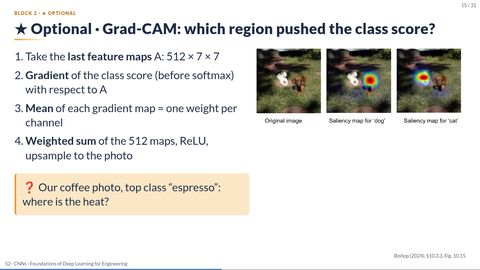

<sub>Slide 15 · Grad-CAM</sub>

For fast pairs. It works after `S2·0` alone.

Grad-CAM in three steps, on the output of `layer4` (512 maps of 7 × 7):

1. a **forward hook** keeps the maps `acts` (1, 512, 7, 7); a **gradient hook** keeps `grads`, the gradient of the class score with respect to these maps (same shape),
2. the **weight** of each map is the mean of its gradient over the 7 × 7 positions (dimensions 2 and 3),
3. the heat map is the weighted **sum over the 512 maps** (dimension 1), then a ReLU (keep only what pushes the score up).

We use the coffee photo: which part of it makes ResNet18 say "espresso"?

The hooks are written for you. Fill in the two dimensions of the mean and the dimension of the sum.

- in: the coffee photo (1, 3, 224, 224) and a class number (None = the top-1 class),
- out: `cam`, the heat map (1, 7, 7): one number per region of the photo; large = this region raised the class score.

In [ ]:
# ✏️ S2·L2·OPT1
def grad_cam(x, class_idx=None):
    """Grad-CAM map (1, 7, 7) of image x (pixels in [0, 1]) for one class (None = the top-1 class)."""
    store = {}                                   # the two hooks put acts and grads here

    def save_grad(g):                            # gradient hook: d(score) / d(acts), called by backward()
        store["grads"] = g

    def save_acts(module, inp, out):             # forward hook on layer4, called by the forward pass
        store["acts"] = out                      # (1, 512, 7, 7): 512 maps of 7 × 7
        out.register_hook(save_grad)             # ask for the gradient of these maps too

    handle = resnet.layer4.register_forward_hook(save_acts)
    try:
        logits = resnet(imagenet_norm(x))        # (1, 1000): one score per class
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()
        logits[0, class_idx].backward()          # gradient of ONE class score
    finally:
        handle.remove()                          # remove the hook, even if something failed
        resnet.zero_grad(set_to_none=True)       # forget the gradients of the weights (we do not train)
    acts = store["acts"].detach()                # (1, 512, 7, 7)
    grads = store["grads"]                       # (1, 512, 7, 7)
    # TODO: average over the 7 × 7 positions: which two dimensions of (1, 512, 7, 7) are height and width?
    w = grads.mean(dim=(___, ___), keepdim=True)               # (1, 512, 1, 1): one weight per map
    # TODO: add up the 512 weighted maps: which dimension counts the maps?
    cam = F.relu((w * acts).sum(dim=___))                      # (1, 7, 7): weighted sum of the 512 maps
    return cam, class_idx


# None = the top-1 class (espresso). Try another one, e.g. CLASS = categories.index("cup")
CLASS = None
cam, cam_cls = grad_cam(PHOTOS_224["coffee"], CLASS)
print("class:", categories[cam_cls], "· map", tuple(cam.shape))
cam_scaled = cam[0] / cam.max()                  # (7, 7) scaled so that the largest value is 1
print(cam_scaled.cpu().numpy().round(2))

In [ ]:
# ▶ S2·L2·OPT1·check
check(tuple(cam.shape) == (1, 7, 7), "Grad-CAM map (1, 7, 7): one value per position of layer4",
      "mean over the positions (dims 2 and 3), sum over the 512 maps (dim 1)")
check(cam.max().item() > 0, "the map has positive values (the ReLU keeps what pushes the score up)",
      "F.relu((w * acts).sum(dim=1))")
flat_index = cam[0].argmax().item()             # position of the largest value among the 49 cells (0 to 48)
hot_cell = divmod(flat_index, 7)                # -> (row, col) in the 7 × 7 grid
print(f"★ Grad-CAM hottest cell (row, col) = {hot_cell}")

# plotting only: you can skip this (the 7 × 7 map is stretched to 224 × 224 and drawn over the photo)
heat = F.interpolate(cam[None], size=224, mode="bilinear", align_corners=False)[0, 0].cpu()
fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
ax[0].imshow(PHOTOS_224["coffee"][0].permute(1, 2, 0).cpu()); ax[0].set_title("photo")
ax[1].imshow(cam[0].cpu(), cmap="jet"); ax[1].set_title("Grad-CAM 7 × 7")
ax[1].set_xticks(range(7)); ax[1].set_yticks(range(7))
ax[2].imshow(PHOTOS_224["coffee"][0].permute(1, 2, 0).cpu()); ax[2].imshow(heat, cmap="jet", alpha=0.45)
ax[2].set_title(f"overlay · {categories[cam_cls]}")
ax[0].axis("off"); ax[2].axis("off"); plt.tight_layout(); plt.show()
if CLASS is None:                                # reference file: only for the top-1 class
    REF["lab2"].update(cam_class=categories[cam_cls], cam_cell=list(hot_cell))
    save_reference(quiet=True)

💬 **★ Lab 2 · Q1.** (after ★ Optional A) Where is the heat for "espresso": on the cup, the coffee and its crema, the saucer, the table? Is it where you expected? Set `CLASS = categories.index("cup")` or a class that is not in the photo (for example `"tiger cat"`) in ★ Optional A, rerun it and its ✅ cell, and compare.

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ✏️ ★ Optional B · Fool the network (FGSM)

*Slide: "★ Optional · A trained CNN can be fooled by noise you cannot see" (slide 17).*

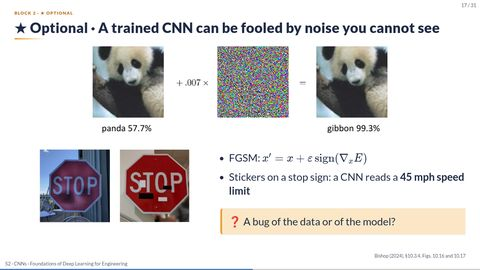

<sub>Slide 17 · fooled</sub>

For fast pairs. It works after `S2·0` alone: you do not need ★ Optional A.

The **fast gradient sign method** moves every pixel by a tiny amount ε in the direction that increases the loss:

$$x_{adv} = \text{clip}\big(x + \varepsilon \cdot \text{sign}(\nabla_x \text{loss}),\ 0,\ 1\big)$$

Pixels are in [0, 1], so ε = 0.01 means 1% of the full range per pixel. The normalization is inside the wrapper `Normalized`, so we change real pixels. We attack the coffee photo ("espresso"). Fill in the step: ε times the **sign** of the gradient.

- in: the coffee photo (1, 3, 224, 224), pixels in [0, 1], and the list of ε values,
- out: for each ε, the new top-1 class and its probability; then the smallest ε that changes the class.

**Predict first** (slide 16): how much must each pixel change to change the class? A 50%, B 10%, C 1% or less.

In [ ]:
# ✏️ S2·L2·OPT2
class Normalized(nn.Module):
    """Pixels in [0, 1] in, logits out: the ImageNet normalization is inside the model."""
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):                            # x: pixels in [0, 1]
        return self.model(imagenet_norm(x))


net = Normalized(resnet).eval()
EPS = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]   # 0.001 = 0.1% of the pixel range
x = PHOTOS_224["coffee"].clone().requires_grad_(True)   # (1, 3, 224, 224); we want the gradient w.r.t. x
logits = net(x)                                      # (1, 1000)
y_clean = logits.argmax(dim=1)                       # the class the network sees now
loss = F.cross_entropy(logits, y_clean)
loss.backward()                                      # x.grad: how the loss changes with each pixel
resnet.zero_grad(set_to_none=True)                   # we do not train: forget the weight gradients
probs_clean = F.softmax(logits.detach(), dim=1)[0]   # (1000,) probabilities
p_clean = probs_clean[y_clean].item()
print(f"clean photo: {categories[y_clean.item()]} ({100 * p_clean:.1f}%)")

fgsm = []                                            # one row per eps: (eps, class, probability, photo)
with torch.no_grad():
    for eps in EPS:
        # TODO: move every pixel by eps in the direction of the gradient: which function keeps only +1 or -1?
        x_adv = (x + ___ * x.grad.___()).clamp(0, 1)    # every pixel moves by +eps or -eps
        probs = F.softmax(net(x_adv), dim=1)[0]      # (1000,) probabilities for the changed photo
        top1, conf = probs.argmax().item(), probs.max().item()
        fgsm.append((eps, top1, conf, x_adv))
        print(f"ε = {eps:<6} top-1: {categories[top1]:22s} {100 * conf:5.1f}%")

In [ ]:
# ▶ S2·L2·OPT2·check
changed = []                                     # the rows where the top-1 class is not the clean one
for row in fgsm:
    if row[1] != y_clean.item():
        changed.append(row)
check(abs((fgsm[0][3] - x).abs().max().item() - EPS[0]) < 1e-4 or EPS[0] == 0,
      "each pixel moved by at most ε", "x_adv = x + eps * x.grad.sign(), then clamp to [0, 1]")
check(len(changed) > 0, "a change you cannot see changes the class", "use the sign of x.grad, times eps")
if changed:
    eps_found, cls_found, conf_found, x_found = changed[0]    # the smallest eps that changed the class
    delta = (x_found - x.detach())[0]                         # the noise we added: (3, 224, 224)
    # plotting only: you can skip this
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
    ax[0].imshow(x.detach()[0].permute(1, 2, 0).cpu())
    ax[0].set_title(f"clean: {categories[y_clean.item()]} ({100 * p_clean:.0f}%)")
    ax[1].imshow((0.5 + 0.5 * delta / eps_found).permute(1, 2, 0).cpu().clamp(0, 1))
    ax[1].set_title(f"noise ±{eps_found} (scaled to be visible)")
    ax[2].imshow(x_found[0].permute(1, 2, 0).cpu())
    ax[2].set_title(f"ε = {eps_found}: {categories[cls_found]} ({100 * conf_found:.0f}%)")
    for a in ax:
        a.axis("off")
    plt.tight_layout(); plt.show()
    REF["lab2"].update(fgsm_eps=eps_found, fgsm_class=categories[cls_found])
    save_reference(quiet=True)                                # reference file: you can skip this
    print(f"★ FGSM smallest ε {eps_found} · new class {categories[cls_found]}")
else:
    print("★ FGSM: no ε in the list changed the class")

❓ **★ Lab 2 · Q2.** (after ★ Optional B) The adversarial photo looks exactly like the clean one to you, yet the network changes its answer. Is this a weakness (a) of the photo, or (b) of the model?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ★ Optional · Grad-CAM on the cat and the astronaut

For fast pairs, after ★ Optional A (it uses its function `grad_cam`). On the cat, the face fills the photo, so the map is spread almost everywhere (compare with the coffee cup). The astronaut photo has several objects and no ImageNet class "astronaut": which class does ResNet18 choose, and where does it look?

In [ ]:
# ▶ S2·L2·STAR
if "grad_cam" not in globals():                         # grad_cam is defined in ★ Optional A
    print("do ★ Optional A first: this cell uses its grad_cam function")
else:
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    for a, name in zip(ax, ("cat", "astronaut")):
        cam_o, cls_o = grad_cam(PHOTOS_224[name])            # (1, 7, 7) heat map for the top-1 class
        heat_o = F.interpolate(cam_o[None], size=224, mode="bilinear", align_corners=False)[0, 0].cpu()
        share = (cam_o > 0.5 * cam_o.max()).float().mean().item()
        print(f"{name}: {categories[cls_o]} · {100 * share:.0f}% of the 49 cells are above half the maximum")
        a.imshow(PHOTOS_224[name][0].permute(1, 2, 0).cpu()); a.imshow(heat_o, cmap="jet", alpha=0.45)
        a.set_title(f"{name} · {categories[cls_o]}"); a.axis("off")
    plt.tight_layout(); plt.show()

## Lab 3 · Transfer learning: reuse 11 million weights

Every pair does this lab: 3a until 14:46, 3b until 15:03.

ResNet18 already knows edges, textures and object parts from 1.28 million ImageNet photos. We keep this **backbone** and give it a new **head** for the 10 classes of CIFAR-10. Two recipes:

- **Recipe 1 · feature extraction** (Lab 3a): freeze the backbone, train only the new head (5,130 parameters).
- **Recipe 2 · fine-tuning** (Lab 3b): then unfreeze everything and train all 11 million weights with a learning rate 10 times smaller.

**You report:** accuracy (%) after feature extraction (3a); after fine-tuning (3b); with a learning rate 100 times too large (🔬)

### ▶ L3·1 · 5,000 CIFAR-10 photos, and a CNN from scratch to beat

*Slide: "Keep the backbone" (slide 21).*

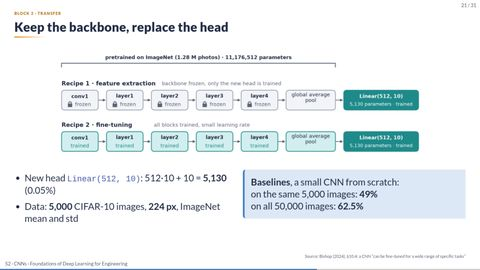

<sub>Slide 21 · Keep the backbone</sub>

- We take only **5,000 training photos** (500 per class) and 2,000 validation photos (200 per class, from the test set). They stay 32 × 32 on the GPU.
- ResNet18 expects 224 × 224 photos normalized like ImageNet: `prep(x)` resizes each batch to 224 and normalizes it, on the fly.
- A baseline: the small ConvNet of the warm-up (67,642 parameters), trained from scratch on the same 5,000 photos for 10 epochs. This is the number to beat.

What comes out: `X3_train` (5000, 3, 32, 32) and `X3_val` (2000, 3, 32, 32) with pixels in [0, 1], their labels `y3_train`, `y3_val`, the function `prep`, and the accuracy of the CNN from scratch.

In [ ]:
# ▶ S2·L3·1
N3_TRAIN, N3_VAL, IMG = (400, 200, 96) if FAST else (5_000, 2_000, 224)


def stratified(y, n, seed=0):
    """Indices of n examples, n/10 of each class, in random order."""
    g = torch.Generator().manual_seed(seed)
    chosen = []
    for c in range(10):
        idx_c = (y == c).nonzero()[:, 0]                       # every index of class c
        shuffled = torch.randperm(len(idx_c), generator=g)     # a random order of them
        chosen.append(idx_c[shuffled[:n // 10]])               # keep n/10 of them
    idx = torch.cat(chosen)                                    # (n,), sorted by class
    return idx[torch.randperm(len(idx), generator=g)]          # mix the classes


tr3 = stratified(CIFAR_Y_TRAIN, N3_TRAIN, seed=0)               # 5,000 indices of training photos
va3 = stratified(CIFAR_Y_TEST, N3_VAL, seed=1)                  # 2,000 indices of test photos
X3_train = (CIFAR_X_TRAIN[tr3].float() / 255).to(device)      # (5000, 3, 32, 32), pixels in [0, 1]
X3_val = (CIFAR_X_TEST[va3].float() / 255).to(device)          # (2000, 3, 32, 32)
y3_train = CIFAR_Y_TRAIN[tr3].to(device)                        # (5000,) labels 0 to 9
y3_val = CIFAR_Y_TEST[va3].to(device)                           # (2000,)
per_class = torch.bincount(y3_train).tolist()                   # how many photos of each class
print(f"train {tuple(X3_train.shape)} · val {tuple(X3_val.shape)} · per class {per_class}")


def prep(x):
    """A batch of 32 × 32 photos in [0, 1] -> IMG × IMG (224), normalized like ImageNet."""
    x = F.interpolate(x, size=(IMG, IMG), mode="bilinear", align_corners=False)   # (N, 3, 224, 224)
    return imagenet_norm(x)                     # the normalization ResNet18 was trained with


print("prep:", tuple(X3_train[:2].shape), "->", tuple(prep(X3_train[:2]).shape))


class SmallConvNet(nn.Module):
    """The warm-up ConvNet (67,642 parameters), written again so that this lab does not need the warm-up."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(16 * 8 * 8, 64), nn.ReLU(), nn.Linear(64, 10))

    def forward(self, x):
        return self.head(self.features(x))               # logits, no softmax


# the baseline: the small CNN trained from scratch on the same 5,000 photos (32 × 32, mean 0 and std 1)
m3 = X3_train.mean(dim=(0, 2, 3), keepdim=True)          # (1, 3, 1, 1): one mean per colour channel
s3 = X3_train.std(dim=(0, 2, 3), keepdim=True)
X3_train_n = (X3_train - m3) / s3
X3_val_n = (X3_val - m3) / s3
set_seed(0)
scratch = SmallConvNet()
fit(scratch, X3_train_n, y3_train, X3_val_n, y3_val, epochs=10, name="from scratch · 5,000 photos")
r_s = result("from scratch · 5,000 photos")
# reference file: you can skip this
REF["lab3"].update(n_train=N3_TRAIN, n_val=N3_VAL, img_size=IMG,
                   scratch5k={"val_acc": round(r_s["val_acc"], 4), "time_s": r_s["time_s"]})
thr = 0.20 if FAST else 0.44                     # reference run (Colab T4): 49.3% (FAST: 30 to 34%)
check(r_s["val_acc"] > thr, f"from scratch on 5,000 photos: {100 * r_s['val_acc']:.1f}% (the number to beat)",
      "rerun this cell")

### ▶ L3·2 · The training loop for transfer learning (read it, then run it)

The same four steps as always (forward, loss, backward, update), with two additions for speed:

- `prep` makes each batch 224 × 224 on the fly (the GPU keeps only the small 32 × 32 photos),
- **mixed precision** on the GPU (`torch.autocast`, float16): about 2 times faster on a T4. It does nothing on a CPU.

`freeze_bn=True` keeps the whole model in eval mode while training (used in Lab 3a).

- `train_tl(model, optimizer, epochs, name)`: in: a model and an optimizer; it trains on the 5,000 photos and prints one line per epoch; out: the validation accuracy (0 to 1) and the time in seconds,
- `evaluate_tl(model)`: the accuracy on the 2,000 validation photos.

You may skip reading the details: the four numbered comments are the important lines.

In [ ]:
# ▶ S2·L3·2
BATCH3 = 64


def amp():
    """Mixed precision (float16) on the GPU; nothing on a CPU."""
    if device == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return contextlib.nullcontext()             # a "with" block that does nothing


@torch.no_grad()                                # no gradients when we only measure
def evaluate_tl(model, batch_size=250):
    """Validation accuracy (0 to 1) on X3_val, in batches."""
    model.eval()
    correct = 0
    for i in range(0, len(X3_val), batch_size):
        xb = X3_val[i:i + batch_size]           # (250, 3, 32, 32)
        yb = y3_val[i:i + batch_size]           # (250,)
        with amp():
            out = model(prep(xb))               # (250, 10): 10 class scores per photo
        correct += (out.argmax(dim=1) == yb).sum().item()
    return correct / len(X3_val)


def train_tl(model, optimizer, epochs, name, freeze_bn=False):
    """Train on X3_train (resized by prep), one line per epoch. Returns dict(val_acc, time_s)."""
    scaler = torch.amp.GradScaler("cuda") if device == "cuda" else None    # float16 needs a loss scaler
    loss_fn = nn.CrossEntropyLoss()
    n, t0 = len(X3_train), time.time()
    for epoch in range(epochs):
        # BatchNorm: train mode updates its running statistics, eval mode keeps the ImageNet ones
        model.eval() if freeze_bn else model.train()
        perm = torch.randperm(n, device=device)          # a new random order every epoch
        total = torch.zeros((), device=device)           # sum of the losses of this epoch
        for i in range(0, n, BATCH3):
            idx = perm[i:i + BATCH3]                     # the indices of one mini-batch of 64 photos
            with amp():
                loss = loss_fn(model(prep(X3_train[idx])), y3_train[idx])     # 1. forward, 2. loss
            optimizer.zero_grad(set_to_none=True)
            if scaler is not None:                       # on the GPU: the scaler protects float16 gradients
                scaler.scale(loss).backward()                                  # 3. backward
                scaler.step(optimizer)                                         # 4. update
                scaler.update()
            else:                                        # on a CPU: the usual two lines
                loss.backward()                                                # 3. backward
                optimizer.step()                                               # 4. update
            total += loss.detach().float() * len(idx)
        acc = evaluate_tl(model)                         # validation accuracy after this epoch
        print(f"{name} · epoch {epoch + 1}/{epochs} · train loss {total.item() / n:.3f} · "
              f"val acc {100 * acc:.1f}% · {time.time() - t0:.0f} s")
    t = round(time.time() - t0, 1)
    # one row for the results table (show_results)
    RESULTS.append(dict(name=name, params=count_params(model), val_acc=acc,
                        errors=int(round((1 - acc) * len(y3_val))), n_val=len(y3_val),
                        epochs=epochs, time_s=t))
    return dict(val_acc=acc, time_s=t)


EPOCHS3 = 1 if FAST else 2
print(f"ready: {len(X3_train):,} training photos, batches of {BATCH3}, images {IMG} × {IMG}, "
      f"mixed precision {'on' if device == 'cuda' else 'off'}")

### ✏️ Lab 3a · TODO 1 · Recipe 1: freeze the backbone, train a new head

*Slide: "Recipe 1" (slide 22).*

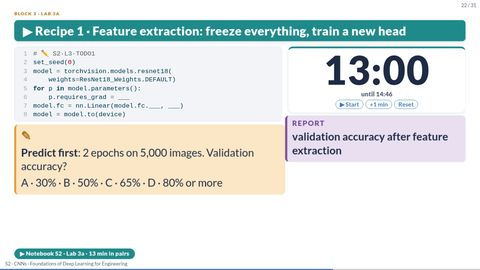

<sub>Slide 22 · Recipe 1</sub>

1. Load ResNet18 with its ImageNet weights (already downloaded in `S2·0`).
2. **Freeze** every parameter: `requires_grad = False` means no gradient and no update.
3. Replace the head: `model.fc` becomes a new `nn.Linear` from the 512 features (`model.fc.in_features`) to our 10 classes. A new layer is trainable by default.

Only the head learns: 512 · 10 + 10 = 5,130 parameters, 0.05% of the network. Training 2 epochs takes about 6 s on a T4.

- in: ResNet18 with its ImageNet weights; its last layer `fc` is Linear(512 → 1000),
- out: the same network with every old weight frozen and a new last layer Linear(512 → 10).

**Predict first** (slide 22): validation accuracy after 2 epochs? A 30%, B 50%, C 65%, D 80% or more.

In [ ]:
# ✏️ S2·L3·TODO1
set_seed(0)
model = torchvision.models.resnet18(weights=ResNet18_Weights.DEFAULT)   # pretrained on ImageNet
for p in model.parameters():
    # TODO: freezing means "no gradient for this parameter": True or False?
    p.requires_grad = ___                                         # freeze: no gradient, no update
# TODO: the new head takes the same number of features as the old one, and gives one score per CIFAR-10 class
model.fc = nn.Linear(model.fc.___, ___)                    # new head: 512 → 10 classes
model = model.to(device)
n_all = sum(p.numel() for p in model.parameters())                    # every parameter, frozen or not
print(f"trainable parameters: {count_params(model):,} of {n_all:,}")

In [ ]:
# ▶ S2·L3·TODO1·check
check(count_params(model) == 5130, "only the new head is trainable: 512·10 + 10 = 5,130 parameters",
      "requires_grad = False for every old parameter; the new Linear(512, 10) is created after the loop")
check(model.fc.out_features == 10, "the head has 10 outputs, one per CIFAR-10 class", "nn.Linear(512, 10)")

In [ ]:
# ▶ S2·L3·TODO1·train
set_seed(0)
trainable = []                                   # only the parameters that learn (the new head)
for p in model.parameters():
    if p.requires_grad:
        trainable.append(p)
optimizer = torch.optim.Adam(trainable, lr=1e-3)
# freeze_bn=True: the frozen backbone keeps its ImageNet BatchNorm statistics,
# so the features the head learns from do not move
fe = train_tl(model, optimizer, EPOCHS3, "feature extraction (head only)", freeze_bn=True)

fe_state = {}                                    # a copy of every weight now, to restart from it in TODO 3
for k, v in model.state_dict().items():
    fe_state[k] = v.detach().clone()
# reference file, self-check and REPORT line
REF["lab3"]["fe"] = {"val_acc": round(fe["val_acc"], 4), "time_s": fe["time_s"],
                     "trainable": count_params(model)}
save_reference(quiet=True)
thr = 0.18 if FAST else 0.80                     # reference run (Colab T4): 83.5% (FAST: 28 to 31%)
check(fe["val_acc"] > thr,
      f"feature extraction: {100 * fe['val_acc']:.1f}% after training only 5,130 parameters",
      "TODO 1 first (trainable must be 5,130), then rerun this cell")
s5k = REF["lab3"]["scratch5k"]["val_acc"]
report_line("Lab 3a", f"feature extraction accuracy in % · {100 * fe['val_acc']:.1f}"
            + (f" (from scratch: {100 * s5k:.1f})" if s5k else ""))

❓ **Lab 3a · Q1.** Your prediction (A 30%, B 50%, C 65%, D 80% or more) and your result. Only 5,130 parameters learned, from 5,000 photos. Why is this so much better than the CNN trained from scratch on the same photos?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ✏️ Lab 3b · TODO 2 · Recipe 2: unfreeze everything, learning rate 10 times smaller

*Slide: "Recipe 2" (slide 23).*

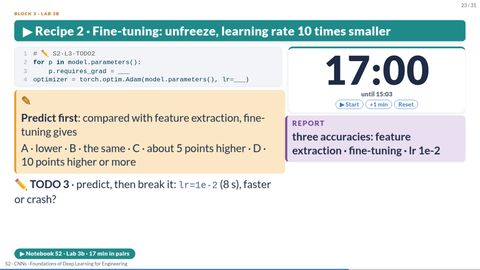

<sub>Slide 23 · Recipe 2</sub>

We continue from the model of Lab 3a (its head is already trained). Now **every** parameter learns, with Adam and a learning rate of 1e-4, 10 times smaller than for the head: the pretrained weights are already good, so we only want to adjust them a little. Training 2 epochs takes about 16 s on a T4.

- in: the model of Lab 3a (frozen backbone, trained head),
- out: the same model with every parameter trainable (11,181,642), and a new optimizer for all of them.

**Predict first** (slide 23): compared with feature extraction, the accuracy will be A lower, B the same, C about 5 points higher, D 10 points higher or more.

In [ ]:
# ✏️ S2·L3·TODO2
for p in model.parameters():
    # TODO: unfreeze: every parameter gets a gradient again
    p.requires_grad = ___                                       # unfreeze every layer
# TODO: the head used lr = 1e-3; fine-tuning uses a learning rate 10 times smaller
optimizer = torch.optim.Adam(model.parameters(), lr=___)        # 10 times smaller than for the head
print(f"trainable parameters: {count_params(model):,}")

In [ ]:
# ▶ S2·L3·TODO2·check
check(count_params(model) == 11_181_642,
      "all 11,181,642 parameters are trainable (11,176,512 backbone + 5,130 head)",
      "requires_grad = True for every parameter; run TODO 1 and its training cell first")
check(abs(optimizer.param_groups[0]["lr"] - 1e-4) < 1e-12, "learning rate 1e-4, 10 times smaller than 1e-3",
      "lr=1e-4")

In [ ]:
# ▶ S2·L3·TODO2·train
set_seed(0)
ft = train_tl(model, optimizer, EPOCHS3, "fine-tuning (all layers, lr 1e-4)")
# reference file, self-check and REPORT line
REF["lab3"]["ft"] = {"val_acc": round(ft["val_acc"], 4), "time_s": ft["time_s"],
                     "trainable": count_params(model)}
save_reference(quiet=True)
thr = 0.30 if FAST else 0.86                     # reference run (Colab T4): 90.1% (FAST: 45 to 46%)
check(ft["val_acc"] > thr, f"fine-tuning: {100 * ft['val_acc']:.1f}%",
      "TODO 2: lr=1e-4 and every layer trainable")
fe_acc = REF["lab3"]["fe"]["val_acc"]
if fe_acc:
    report_line("Lab 3b", f"accuracy in % · feature extraction {100 * fe_acc:.1f} · "
                          f"fine-tuning {100 * ft['val_acc']:.1f}")
else:
    report_line("Lab 3b", f"fine-tuning accuracy in % · {100 * ft['val_acc']:.1f}")

### 🔬 Lab 3b · TODO 3 · A learning rate 100 times too large

We restart from the end of Lab 3a (`fe_state`: pretrained backbone + trained head), unfreeze everything, and fine-tune for 1 epoch with lr = 1e-2, 100 times larger than in TODO 2.

**❓ Predict before you run:** you just reached about 90% with `lr = 1e-4`. Bet with your partner: with `lr = 1e-2`, will accuracy go up, stay near 80%, or collapse below 20%?

- in: `fe_state`, the weights saved at the end of Lab 3a,
- out: one epoch of training with lr = 1e-2 and its validation accuracy.

In [ ]:
# ✏️ S2·L3·TODO3
model_bad = torchvision.models.resnet18()                 # same architecture; the weights come from fe_state
model_bad.fc = nn.Linear(512, 10)
model_bad.load_state_dict(fe_state)                       # restart from the end of Lab 3a
model_bad = model_bad.to(device)                          # every parameter is trainable
# TODO: 100 times larger than the 1e-4 of TODO 2
optimizer_bad = torch.optim.Adam(model_bad.parameters(), lr=___)    # 100 times larger than in TODO 2
set_seed(0)
bad = train_tl(model_bad, optimizer_bad, 1, "fine-tuning, lr 1e-2 (too large)")

In [ ]:
# ▶ S2·L3·TODO3·check
# reference file: you can skip these two lines
REF["lab3"]["bad_lr"] = {"val_acc": round(bad["val_acc"], 4), "time_s": bad["time_s"]}
save_reference(quiet=True)
fe_acc = REF["lab3"]["fe"]["val_acc"] or 1.0        # the accuracy of Lab 3a, to compare with
check(abs(optimizer_bad.param_groups[0]["lr"] - 1e-2) < 1e-12, "learning rate 1e-2", "lr=1e-2")
if FAST:
    print("(FAST mode: collapse not checked)")
else:
    check(bad["val_acc"] < fe_acc - 0.15,
          f"with lr 1e-2 the accuracy falls to {100 * bad['val_acc']:.1f}%, below feature extraction "
          f"({100 * fe_acc:.1f}%)", "lr=1e-2, and restart from fe_state")
report_line("Lab 3b 🔬", f"fine-tuning with lr 1e-2, accuracy in % · {100 * bad['val_acc']:.1f}")

❓ **Lab 3b · Q2.** Why does fine-tuning with lr = 1e-2 end far below feature extraction, although it starts from the same weights?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

💬 **Lab 3b · Q3.** Two engineering projects: (1) 300 chest X-rays labelled by a doctor; (2) 50,000 photos of products in a factory. Which recipe would you use for each, and why?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ★ Optional · Fine-tune only the last block

For fast pairs. A middle way: from `fe_state`, unfreeze only `layer4` and `fc` (the most specific layers) and train with lr 1e-4. Compare the accuracy and the time with full fine-tuning.

In [ ]:
# ▶ S2·L3·STAR
model_l4 = torchvision.models.resnet18()
model_l4.fc = nn.Linear(512, 10)
model_l4.load_state_dict(fe_state)                # restart from the end of Lab 3a
model_l4 = model_l4.to(device)
trainable_l4 = []
for name, p in model_l4.named_parameters():       # name is e.g. "layer4.1.conv2.weight" or "fc.bias"
    p.requires_grad = name.startswith("layer4") or name.startswith("fc")
    if p.requires_grad:
        trainable_l4.append(p)
print(f"trainable parameters: {count_params(model_l4):,}")
set_seed(0)
opt_l4 = torch.optim.Adam(trainable_l4, lr=1e-4)
l4 = train_tl(model_l4, opt_l4, EPOCHS3, "fine-tuning layer4 + fc (lr 1e-4)")
show_results()

## Lab 4 · Upsample, then segment the cat

*Slide: "Lab 4" (slide 30).*

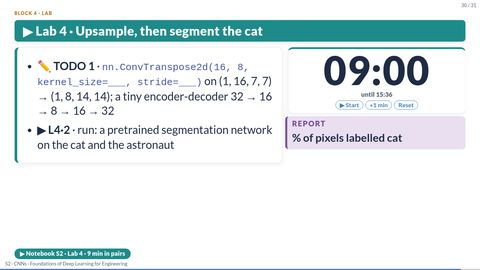

<sub>Slide 30 · Lab 4</sub>

9 minutes, in pairs. Segmentation gives a class to **every pixel**: the output is K × H × W scores (K classes). The encoder makes the maps smaller; the decoder makes them large again with **transpose convolutions**.

Steps: ✏️ TODO 1 (shapes), ▶ L4·2 (a pretrained segmentation network), then the REPORT line.

**You report:** the % of the pixels of the cat photo labelled "cat"

### ✏️ Lab 4 · TODO 1 · A transpose convolution doubles the size

*Slide: "Transpose convolution" (slide 28).*

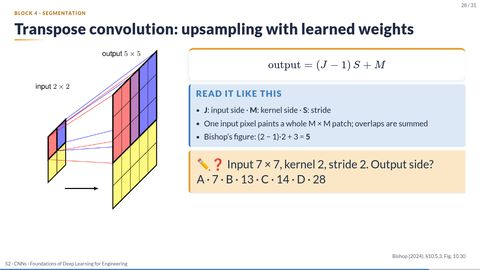

<sub>Slide 28 · Transpose convolution</sub>

Without padding, a transpose convolution gives an output of size (J − 1) · S + M. We want 7 × 7 → 14 × 14 with 16 → 8 channels. Choose the kernel size M and the stride S (hint: M = S).

- in: a batch of 16 feature maps of 7 × 7, shape (1, 16, 7, 7),
- out: 8 maps of 14 × 14, shape (1, 8, 14, 14).

In [ ]:
# ✏️ S2·L4·TODO1
# TODO: (7 − 1)·S + M must be 14, with M = S
up = nn.ConvTranspose2d(16, 8, kernel_size=___, stride=___)
z = torch.randn(1, 16, 7, 7)                      # 16 random maps of 7 × 7 (a batch of one)
up_out = up(z)                                    # should be (1, 8, 14, 14)
print(tuple(z.shape), "->", tuple(up_out.shape), "·", count_params(up), "parameters")

In [ ]:
# ▶ S2·L4·TODO1·check
check(tuple(up_out.shape) == (1, 8, 14, 14), "(7 − 1)·2 + 2 = 14: the transpose convolution doubles H and W",
      "(J − 1)·S + M = 14 with J = 7: kernel_size=2, stride=2")
check(count_params(up) == 520, "16·8·2·2 + 8 = 520 parameters", "kernel_size=2")
REF["lab4"]["up_shape"] = list(up_out.shape)    # reference file

# a tiny encoder-decoder (not trained): 32 → 16 → 8 → 16 → 32, then 21 class scores per pixel
enc_dec = nn.Sequential(
    nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),       # encoder: 32 → 16
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      #          16 → 8
    nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2), nn.ReLU(),   # decoder:  8 → 16
    nn.ConvTranspose2d(16, 21, kernel_size=2, stride=2))              #          16 → 32, 21 classes
h = torch.randn(1, 3, 32, 32)                    # one random "photo" of 32 × 32
print("input", tuple(h.shape))
for layer in enc_dec:                            # run the layers one by one to print every shape
    h = layer(h)
    if not isinstance(layer, nn.ReLU):           # a ReLU does not change the shape: skip its line
        print(f"{layer.__class__.__name__:16s} -> {tuple(h.shape)}")
check(tuple(h.shape) == (1, 21, 32, 32), "21 scores for each of the 32 × 32 pixels: (1, K, H, W)",
      "rerun this cell")

### ▶ L4·2 · A pretrained segmentation network on the cat and the astronaut

`lraspp_mobilenet_v3_large` is a small segmentation network (3.2 million parameters) trained on 21 classes (background, person, cat, dog, car, ...). It downloads 13 MB the first time. For each pixel we take the class with the largest score (argmax) and colour it.

- in: a photo at its own size (1, 3, H, W), pixels in [0, 1],
- out: 21 scores per pixel (1, 21, H, W); argmax gives the mask (H, W), one class number per pixel.

In [ ]:
# ▶ S2·L4·2
SEG_OK = False
try:
    from torchvision.models.segmentation import lraspp_mobilenet_v3_large, LRASPP_MobileNet_V3_Large_Weights
    seg_weights = LRASPP_MobileNet_V3_Large_Weights.DEFAULT
    seg_model = lraspp_mobilenet_v3_large(weights=seg_weights).eval().to(device)
    VOC = seg_weights.meta["categories"]                  # 21 classes, VOC[0] = background
    SEG_OK = True
except Exception as e:
    print("Could not load the segmentation network (no internet?):", repr(e)[:120])
    print("Skip this cell: look at slide 30 instead.")

if SEG_OK:
    masks = {}
    with torch.no_grad():
        for name in ("cat", "astronaut"):
            out = seg_model(imagenet_norm(PHOTOS_FULL[name]))["out"]      # (1, 21, H, W) scores
            masks[name] = out.argmax(dim=1)[0].cpu()                     # (H, W) class of each pixel
            print(f"{name:10s} scores {tuple(out.shape)} -> mask {tuple(masks[name].shape)}")
    # plotting only: you can skip this (background pixels are left uncoloured)
    cmap = plt.get_cmap("tab20", 21)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
    for a, (name, m) in zip(ax, masks.items()):
        a.imshow(PHOTOS_FULL[name][0].permute(1, 2, 0).cpu())
        a.imshow(np.ma.masked_where(m.numpy() == 0, m.numpy()), cmap=cmap, vmin=0, vmax=20, alpha=0.55)
        present = [c for c in m.unique().tolist() if c != 0]
        shares = [f"{VOC[c]} {100 * (m == c).float().mean():.0f}%" for c in present]
        a.set_title(name + ": " + ", ".join(shares), fontsize=9)
        a.axis("off")
    plt.tight_layout(); plt.show()
    is_cat = (masks["cat"] == VOC.index("cat")).float()     # 1.0 where the pixel is labelled "cat"
    cat_pct = 100 * is_cat.mean().item()                     # the share of such pixels, in %
    REF["lab4"]["cat_pct"] = round(cat_pct, 1)
    check(cat_pct > 73, f"{cat_pct:.1f}% of the pixels of the cat photo are labelled 'cat'",
          "rerun this cell")
    report_line("Lab 4", f"pixels labelled cat in % · {cat_pct:.1f}")
save_reference(quiet=True)

❓ **Lab 4 · Q1.** A segmentation network for 21 classes gets one photo of 224 × 224. What is the shape of its output scores?
(a) (1, 21)  (b) (1, 21, 224, 224)  (c) (1, 3, 224, 224)  (d) (1, 224, 224)

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ★ Optional · Photos without a known object

For fast pairs. The coffee cup and the rocket are not among the 21 classes. What does the network do with them?

In [ ]:
# ▶ S2·L4·STAR
if SEG_OK:
    with torch.no_grad():
        for name in ("coffee", "rocket"):
            out = seg_model(imagenet_norm(PHOTOS_FULL[name]))["out"]      # (1, 21, H, W)
            m = out.argmax(dim=1)[0].cpu()                               # (H, W) mask
            parts = []
            for c in m.unique().tolist():                                # every class that appears
                parts.append(f"{VOC[c]} {100 * (m == c).float().mean():.1f}%")
            print(name, "·", ", ".join(parts))

## Summary

| Lab | Idea | PyTorch line |
|:-|:-|:-|
| Warm-up | a CNN beats an MLP with a third of the parameters | `nn.Conv2d(3, 8, 3, padding=1)` |
| 1 · Architectures | VGG-16 keeps 89% of its weights in FC layers; ResNet adds the input back and its head is tiny | `F.relu(x + self.f(x))` |
| 2 · What CNNs learn | first layers see edges and colours; one cell of layer4 stands for 32 × 32 pixels of the photo; ★ Grad-CAM shows where the class score comes from, and tiny noise can fool a CNN | `maps["layer4"].shape[1:]`; ★ `grads.mean(dim=(2, 3))`, `x + eps * x.grad.sign()` |
| 3 · Transfer | freeze the backbone and train a new head, then unfreeze with a 10 times smaller learning rate | `p.requires_grad = False`, `model.fc = nn.Linear(512, 10)` |
| 4 · Segmentation | a class for every pixel; transpose convolutions upsample | `nn.ConvTranspose2d(16, 8, 2, stride=2)` |

The last cell prints all your REPORT lines and your results table.

In [ ]:
# ▶ S2·END
report()
print()
show_results()
save_reference()